# H&M Retail Intelligence: Customer Behavior, Sales Performance & Product Insights

## Objetivo general

Analizar la actividad comercial de H&M mediante el estudio de las transacciones, el comportamiento de los clientes, el rendimiento de los productos y los canales de venta, con el propósito de identificar patrones relevantes y formular recomendaciones de negocio basadas en datos.

## Objetivos específicos

**1. Analizar la evolución temporal de la actividad comercial.**

Estudiar la evolución mensual de las transacciones, identificar los periodos de mayor y menor actividad y comparar los principales indicadores comerciales.

**2. Comprender el comportamiento de compra de los clientes.**

Analizar los perfiles demográficos de los compradores, la distribución de su actividad y las posibles diferencias según el estado de pertenencia al club.

**3. Evaluar el rendimiento de los productos y categorías.**

Identificar los artículos más vendidos, comparar categorías, líneas comerciales y grupos de prendas, y estudiar las preferencias de compra de los distintos segmentos de edad.

**4. Comparar los canales de venta.**

Examinar las diferencias en volumen de artículos vendidos, actividad temporal, perfiles de compradores y categorías de productos entre los canales registrados.

## Pregunta principal de investigación

**¿Qué patrones de compra, perfiles de clientes, categorías de productos y canales comerciales caracterizan la actividad de H&M durante el periodo analizado, y qué oportunidades de mejora pueden identificarse a partir de ellos?**

## Metodología

El proyecto se desarrollará en tres etapas:

1. **Python:** exploración, evaluación de calidad, limpieza, transformación y preparación de los datasets.
2. **SQL:** integración de las tablas y análisis de los indicadores comerciales mediante consultas.
3. **Tableau:** construcción de visualizaciones interactivas y comunicación de los principales hallazgos.

## Alcance y limitaciones

El análisis se centrará inicialmente en el periodo comprendido entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020.

Cada registro de transacción representa un artículo adquirido y no necesariamente un pedido completo.

Los precios del dataset están normalizados, por lo que no se interpretarán directamente como ingresos expresados en euros.

Los resultados permitirán identificar asociaciones y patrones comerciales, pero no establecer relaciones causales.

La estrategia definitiva de reducción de datos se determinará considerando los objetivos del análisis y la viabilidad técnica de su procesamiento en MySQL Workbench.

## 2. Exploración inicial de los datos (EDA)

En esta fase se examinará la estructura de los tres datasets originales para conocer sus dimensiones, variables y tipos de datos, así como detectar posibles problemas de calidad antes de realizar cualquier transformación.

### 2.1. Importación de librerías y localización de archivos

En primer lugar, se importa la librería pandas, que permite trabajar con datos estructurados mediante DataFrames.

A continuación, se definen las rutas de los tres datasets originales: clientes, artículos y transacciones.

Esta comprobación permite verificar que los archivos están disponibles antes de comenzar el análisis exploratorio.

In [1]:
import pandas as pd
from pathlib import Path

# Definir la carpeta principal del proyecto
proyecto = Path.cwd().parent

# Definir las rutas de los datasets originales
ruta_clientes = proyecto / "data/raw/customers.csv"
ruta_articulos = proyecto / "data/raw/articles.csv"
ruta_transacciones = proyecto / "data/raw/transactions_train.csv"

# Comprobar que los archivos existen
print("Clientes:", ruta_clientes.exists())
print("Artículos:", ruta_articulos.exists())
print("Transacciones:", ruta_transacciones.exists())


Clientes: True
Artículos: True
Transacciones: True



### 2.2. Exploración del dataset de clientes

El dataset `customers.csv` contiene información sobre los clientes de H&M.

El objetivo de esta primera exploración es conocer la estructura del archivo, identificar las variables disponibles y comprobar sus dimensiones.

Esta información permitirá determinar qué variables pueden resultar útiles para analizar el perfil de los consumidores y sus hábitos de compra.

In [2]:

# Cargar el dataset de clientes
df_clientes = pd.read_csv(ruta_clientes)

# Mostrar las primeras cinco filas
display(df_clientes.head())

# Consultar las dimensiones del dataset
print("Dimensiones:", df_clientes.shape)

# Mostrar los nombres de las columnas
print("\nColumnas disponibles:")
print(df_clientes.columns.tolist())


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


Dimensiones: (1371980, 7)

Columnas disponibles:
['customer_id', 'FN', 'Active', 'club_member_status', 'fashion_news_frequency', 'age', 'postal_code']



#### Resultados de la exploración inicial

El dataset de clientes contiene 1.371.980 registros y 7 variables.

Cada registro corresponde a un cliente identificado mediante `customer_id`.

Las variables incluyen información demográfica, como la edad, y características relacionadas con la pertenencia al club y las comunicaciones comerciales de H&M.

En las primeras filas se observan valores ausentes en algunas variables, por lo que será necesario realizar un análisis de valores nulos antes de preparar los datos.

La variable `customer_id` permitirá relacionar la información de clientes con el historial de transacciones mediante SQL.



### 2.3. Calidad de los datos de clientes

Antes de realizar transformaciones, se analizarán los tipos de datos, los valores ausentes y la existencia de identificadores duplicados.

Estas comprobaciones permiten detectar posibles problemas que podrían afectar a los resultados del análisis.

In [3]:

# Consultar la estructura y los tipos de datos
df_clientes.info()

# Calcular los valores nulos por columna
print("\nValores nulos por columna:")
print(df_clientes.isnull().sum())

# Calcular el porcentaje de valores nulos
print("\nPorcentaje de valores nulos:")
print((df_clientes.isnull().sum() / len(df_clientes) * 100).round(2))

# Comprobar identificadores duplicados
print("\nClientes con ID duplicado:")
print(df_clientes["customer_id"].duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1371980 non-null  str    
 1   FN                      476930 non-null   float64
 2   Active                  464404 non-null   float64
 3   club_member_status      1365918 non-null  str    
 4   fashion_news_frequency  1355969 non-null  str    
 5   age                     1356119 non-null  float64
 6   postal_code             1371980 non-null  str    
dtypes: float64(3), str(4)
memory usage: 256.7 MB

Valores nulos por columna:
customer_id                    0
FN                        895050
Active                    907576
club_member_status          6062
fashion_news_frequency     16011
age                        15861
postal_code                    0
dtype: int64

Porcentaje de valores nulos:
customer_id                0.00
FN                  


#### Resultados del análisis de calidad

El dataset contiene 1.371.980 clientes y 7 variables.

El identificador `customer_id` no presenta valores nulos ni duplicados, por lo que puede utilizarse como clave para relacionar los clientes con sus transacciones.

Las variables `FN` y `Active` presentan porcentajes elevados de valores ausentes, del 65,24 % y 66,15 %, respectivamente.

Por otro lado, la variable `age` presenta un 1,16 % de valores nulos, mientras que `club_member_status` y `fashion_news_frequency` tienen porcentajes inferiores al 2 %.

El código postal no presenta valores ausentes, pero está anonimizado, lo que limita su utilidad para un análisis geográfico.

En esta fase no se eliminarán registros ni se sustituirán valores nulos. Las decisiones de limpieza se tomarán posteriormente, teniendo en cuenta los objetivos del proyecto.


### 2.4. Análisis exploratorio de la edad

La edad es una variable relevante para segmentar a los clientes y analizar posibles diferencias en sus hábitos de compra.

Se examinarán sus principales estadísticas descriptivas, incluyendo la media, mediana, valores mínimos y máximos.

También se analizará su distribución para identificar posibles valores atípicos antes de definir los grupos de edad que se utilizarán en el análisis comercial.

In [4]:

# Estadísticas descriptivas de la edad
print("Estadísticas de edad:")
display(df_clientes["age"].describe())

# Número de clientes menores de 16 años
print("Clientes menores de 16 años:")
print((df_clientes["age"] < 16).sum())

# Número de clientes mayores de 100 años
print("\nClientes mayores de 100 años:")
print((df_clientes["age"] > 100).sum())


Estadísticas de edad:


count    1.356119e+06
mean     3.638696e+01
std      1.431363e+01
min      1.600000e+01
25%      2.400000e+01
50%      3.200000e+01
75%      4.900000e+01
max      9.900000e+01
Name: age, dtype: float64

Clientes menores de 16 años:
0

Clientes mayores de 100 años:
0



#### Resultados del análisis de edad

De los 1.371.980 clientes registrados, 1.356.119 disponen de información sobre su edad.

La edad media es de 36,39 años, mientras que la mediana se sitúa en 32 años. Esta diferencia sugiere una ligera asimetría hacia edades más elevadas.

El 50 % central de los clientes tiene entre 24 y 49 años, según los cuartiles obtenidos.

Las edades registradas oscilan entre los 16 y los 99 años. No se han detectado registros inferiores a 16 años ni superiores a 100 años.

Se han identificado 15.861 clientes sin información de edad. Estos registros se conservarán para no perder información sobre sus posibles transacciones.

Posteriormente, se crearán grupos de edad para facilitar la segmentación y comparación del comportamiento de compra.


### 2.5. Distribución de edades

Se representa la distribución de edades mediante un histograma para identificar los intervalos con mayor concentración de clientes.

Esta visualización complementa las estadísticas descriptivas y facilita la comprensión de la estructura demográfica del dataset.

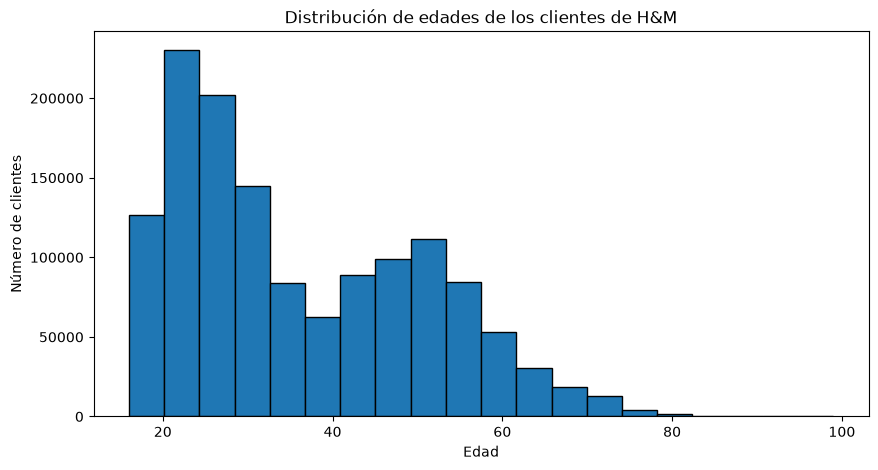

In [5]:

import matplotlib.pyplot as plt

# Crear el histograma de edades
plt.figure(figsize=(10, 5))

plt.hist(
    df_clientes["age"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribución de edades de los clientes de H&M")
plt.xlabel("Edad")
plt.ylabel("Número de clientes")

plt.show()



#### Interpretación de la distribución de edades

El histograma muestra que la distribución de edades de los clientes de H&M no es uniforme.

Se observa una mayor concentración de clientes entre los 20 y los 30 años, especialmente en torno a los 20-25 años.

También se identifica una segunda concentración de clientes aproximadamente entre los 45 y los 55 años.

A partir de los 60 años, la frecuencia disminuye progresivamente, siendo menos habituales los clientes de edades avanzadas.

Estos resultados sugieren diferencias en la composición demográfica de la base de clientes.

Sin embargo, esta distribución no permite determinar qué grupos de edad realizan más compras. Para ello, será necesario relacionar los datos de clientes con las transacciones mediante SQL.


### 2.6. Exploración de variables categóricas

Se analizarán las variables `club_member_status` y `fashion_news_frequency` para conocer sus categorías y la distribución de los clientes.

Esta exploración permitirá valorar si estas variables aportan información relevante a las preguntas de negocio del proyecto.

In [6]:

# Distribución del estado de pertenencia al club
print("Estado de pertenencia al club:")
print(df_clientes["club_member_status"].value_counts(dropna=False))

# Distribución de frecuencia de noticias de moda
print("\nFrecuencia de noticias de moda:")
print(df_clientes["fashion_news_frequency"].value_counts(dropna=False))


Estado de pertenencia al club:
club_member_status
ACTIVE        1272491
PRE-CREATE      92960
NaN              6062
LEFT CLUB         467
Name: count, dtype: int64

Frecuencia de noticias de moda:
fashion_news_frequency
NONE         877711
Regularly    477416
NaN           16011
Monthly         842
Name: count, dtype: int64



#### Resultados del análisis de variables categóricas

La variable `club_member_status` muestra que la mayoría de los clientes tiene estado `ACTIVE` (92,75 %), seguida de `PRE-CREATE` (6,78 %). La categoría `LEFT CLUB` presenta una frecuencia muy reducida.

En cuanto a `fashion_news_frequency`, predomina la categoría `NONE` (63,97 %), seguida de `Regularly` (34,80 %).

Tras esta exploración, se considera relevante conservar `club_member_status` para estudiar posibles diferencias en el comportamiento de compra según el estado de pertenencia al club.

Por otro lado, las variables relacionadas con comunicaciones comerciales y el código postal anonimizado no se consideran prioritarias para los objetivos principales del proyecto.

La selección definitiva se realizará durante la fase de preparación de datos, manteniendo los archivos originales sin modificaciones.


### 2.7. Frecuencia de edades

Se analizará el número de clientes por edad para identificar las edades más frecuentes y disponer de información adicional antes de definir los segmentos demográficos.

In [7]:

# Obtener las 10 edades más frecuentes
edades_frecuentes = df_clientes["age"].value_counts().head(10)

print("Las 10 edades más frecuentes:")
print(edades_frecuentes)


Las 10 edades más frecuentes:
age
21.0    67530
24.0    56124
20.0    55196
25.0    54989
23.0    54867
26.0    53658
22.0    51869
27.0    49134
28.0    44294
29.0    40697
Name: count, dtype: int64



#### Resultados de la frecuencia de edades

El análisis de frecuencias muestra que la edad más habitual entre los clientes registrados es 21 años, con 67.530 clientes.

Las diez edades más frecuentes se encuentran entre los 20 y los 29 años, lo que confirma la elevada presencia de clientes jóvenes observada previamente en el histograma.

Estos resultados permiten conocer mejor la composición demográfica de la base de clientes.

Sin embargo, para determinar qué segmentos generan mayor actividad comercial, será necesario relacionar esta información con las transacciones mediante SQL.


### 2.8. Conclusiones del EDA de clientes

El análisis exploratorio del dataset de clientes ha permitido conocer su estructura, distribución demográfica y calidad de los datos.

Se han identificado 1.371.980 clientes, sin valores nulos ni duplicados en `customer_id`.

La edad presenta un 1,16 % de valores ausentes y una concentración destacada de clientes entre los 20 y los 29 años.

Las variables `FN` y `Active` presentan porcentajes elevados de valores nulos, mientras que el código postal anonimizado tiene una utilidad limitada para los objetivos del proyecto.

A partir de estos resultados, se propone conservar tres variables principales:

- `customer_id`: para relacionar clientes y transacciones.
- `age`: para analizar diferencias entre segmentos demográficos.
- `club_member_status`: para estudiar posibles diferencias de compra según el estado de pertenencia al club.

Durante la fase de preparación se definirán los grupos de edad y el tratamiento de los valores ausentes.

Los datos originales se conservarán sin modificaciones.


## 3. Análisis exploratorio del dataset de artículos

### 3.1. Estructura y dimensiones

El dataset `articles.csv` contiene información sobre los artículos de H&M, incluyendo características como el tipo de producto, categoría, color y departamento.

El objetivo de esta exploración es conocer la estructura del archivo, identificar las variables disponibles y evaluar cuáles resultan relevantes para analizar el rendimiento comercial de los productos.

En primer lugar, se examinarán sus dimensiones, columnas y primeros registros.

In [8]:

# Cargar el dataset original de artículos
df_articulos = pd.read_csv(
    ruta_articulos,
    dtype={"article_id": "str"}
)

# Mostrar las primeras cinco filas
display(df_articulos.head())

# Consultar las dimensiones
print("Dimensiones:", df_articulos.shape)

# Mostrar los nombres de las columnas
print("\nColumnas disponibles:")
print(df_articulos.columns.tolist())


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,0108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,0108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,0108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,0110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,0110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


Dimensiones: (105542, 25)

Columnas disponibles:
['article_id', 'product_code', 'prod_name', 'product_type_no', 'product_type_name', 'product_group_name', 'graphical_appearance_no', 'graphical_appearance_name', 'colour_group_code', 'colour_group_name', 'perceived_colour_value_id', 'perceived_colour_value_name', 'perceived_colour_master_id', 'perceived_colour_master_name', 'department_no', 'department_name', 'index_code', 'index_name', 'index_group_no', 'index_group_name', 'section_no', 'section_name', 'garment_group_no', 'garment_group_name', 'detail_desc']



#### Resultados de la exploración inicial de artículos

El dataset contiene 105.542 registros y 25 variables.

Cada fila representa un artículo identificado mediante `article_id`.

Las variables permiten describir los artículos según su nombre, tipo de producto, categoría, línea comercial, sección, color y otras características.

Se observa que diferentes artículos pueden compartir un mismo nombre de producto, por lo que `article_id` será la variable utilizada para identificar cada artículo y relacionarlo con las transacciones mediante SQL.

El dataset contiene tanto códigos numéricos como nombres descriptivos de categorías. Durante la fase de preparación se evaluará qué variables conservar para evitar información redundante y reducir el tamaño del archivo.


### 3.2. Calidad de los datos de artículos

Se analizarán los tipos de datos, los valores ausentes y la existencia de identificadores duplicados en el dataset de artículos.

Estas comprobaciones permitirán evaluar la calidad de la información y detectar posibles problemas antes de seleccionar las variables que se utilizarán en el análisis comercial.

In [9]:

# Consultar la estructura y los tipos de datos
df_articulos.info()

# Calcular los valores nulos por columna
print("\nValores nulos por columna:")
print(df_articulos.isnull().sum())

# Calcular el porcentaje de valores nulos
print("\nPorcentaje de valores nulos:")
print((df_articulos.isnull().sum() / len(df_articulos) * 100).round(2))

# Comprobar identificadores duplicados
print("\nArtículos con ID duplicado:")
print(df_articulos["article_id"].duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  str  
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n


#### Resultados del análisis de calidad de artículos

El dataset contiene 105.542 artículos y 25 variables, de las cuales 10 son numéricas de tipo entero y 15 son de texto.

La variable `article_id` no presenta valores nulos ni identificadores duplicados, por lo que resulta adecuada para identificar cada artículo y relacionarlo con las transacciones.

De las 25 variables, únicamente `detail_desc` presenta valores ausentes: 416 registros, equivalentes al 0,39 % del total.

Dado que la descripción textual no es imprescindible para responder a las preguntas de negocio, estos valores ausentes no requieren eliminar registros.

En general, el dataset presenta una buena calidad en términos de completitud e identificación de artículos.

Durante la fase de preparación se seleccionarán las variables descriptivas y de clasificación necesarias para el análisis, evitando conservar columnas redundantes.


### 3.3. Exploración de las categorías de productos

La variable `product_group_name` clasifica los artículos en grandes grupos de productos.

Se analizará la distribución de artículos por categoría para conocer la composición del catálogo de H&M e identificar las categorías con mayor número de referencias.

Este análisis permitirá seleccionar las variables de clasificación más relevantes para el posterior estudio del rendimiento comercial mediante SQL.

In [10]:

# Contar los artículos por categoría
categorias_productos = df_articulos["product_group_name"].value_counts()

print("Número de categorías:")
print(df_articulos["product_group_name"].nunique())

print("\nArtículos por categoría:")
print(categorias_productos)


Número de categorías:
19

Artículos por categoría:
product_group_name
Garment Upper body       42741
Garment Lower body       19812
Garment Full body        13292
Accessories              11158
Underwear                 5490
Shoes                     5283
Swimwear                  3127
Socks & Tights            2442
Nightwear                 1899
Unknown                    121
Underwear/nightwear         54
Cosmetic                    49
Bags                        25
Items                       17
Furniture                   13
Garment and Shoe care        9
Stationery                   5
Interior textile             3
Fun                          2
Name: count, dtype: int64



#### Resultados de la distribución de categorías

El catálogo de H&M contiene 19 categorías de productos.

La categoría con mayor número de artículos es `Garment Upper body`, con 42.741 referencias, aproximadamente el 40,5 % del total.

Le siguen `Garment Lower body`, `Garment Full body` y `Accessories`. En conjunto, estas cuatro categorías representan aproximadamente el 82,4 % de los artículos registrados.

También existen categorías con una presencia muy reducida, como `Furniture`, `Stationery` o `Fun`.

Estos resultados muestran que el catálogo está concentrado principalmente en categorías de prendas de vestir y accesorios.

Sin embargo, el número de referencias disponibles no permite determinar qué categorías generan mayor actividad comercial. Para ello, será necesario relacionar los artículos con las transacciones mediante SQL.


### 3.4. Exploración de las líneas comerciales

La variable `index_group_name` permite clasificar los artículos según las principales líneas comerciales de H&M.

Se analizará el número de artículos por línea para conocer la composición del catálogo y valorar su utilidad en el posterior análisis de ventas.

Esta información permitirá comparar el rendimiento comercial de las distintas líneas mediante consultas SQL.

In [11]:

# Contar artículos por línea comercial
lineas_comerciales = df_articulos["index_group_name"].value_counts()

print("Número de líneas comerciales:")
print(df_articulos["index_group_name"].nunique())

print("\nArtículos por línea comercial:")
print(lineas_comerciales)


Número de líneas comerciales:
5

Artículos por línea comercial:
index_group_name
Ladieswear       39737
Baby/Children    34711
Divided          15149
Menswear         12553
Sport             3392
Name: count, dtype: int64



#### Resultados de la distribución por líneas comerciales

El catálogo de H&M se organiza en cinco grandes líneas comerciales: `Ladieswear`, `Baby/Children`, `Divided`, `Menswear` y `Sport`.

La línea con mayor número de artículos es `Ladieswear`, con 39.737 referencias (37,65 %), seguida de `Baby/Children`, con 34.711 referencias (32,89 %).

Ambas líneas concentran aproximadamente el 70,5 % de los artículos registrados.

Por otro lado, `Sport` presenta el menor número de referencias, con 3.392 artículos (3,21 %).

Estos resultados describen la composición del catálogo, pero no permiten establecer qué líneas generan más ventas.

Se propone conservar `index_group_name` para comparar posteriormente el rendimiento comercial de las diferentes líneas mediante SQL y Tableau.


### 3.5. Exploración de los grupos de prendas

La variable `garment_group_name` permite clasificar los artículos en grupos de prendas más específicos.

Se analizará el número de categorías existentes y la distribución de artículos entre ellas para evaluar si esta variable aporta información complementaria a `product_group_name` e `index_group_name`.

El objetivo es determinar su utilidad para el análisis comercial y valorar su inclusión en el dataset reducido.

In [12]:

# Contar artículos por grupo de prendas
grupos_prendas = df_articulos["garment_group_name"].value_counts()

print("Número de grupos de prendas:")
print(df_articulos["garment_group_name"].nunique())

print("\nArtículos por grupo de prendas:")
print(grupos_prendas)


Número de grupos de prendas:
21

Artículos por grupo de prendas:
garment_group_name
Jersey Fancy                     21445
Accessories                      11519
Jersey Basic                      8126
Knitwear                          7490
Under-, Nightwear                 7441
Trousers                          6727
Blouses                           5838
Shoes                             5145
Dresses Ladies                    4874
Outdoor                           4501
Unknown                           3873
Trousers Denim                    3100
Swimwear                          2787
Socks and Tights                  2272
Shirts                            2116
Woven/Jersey/Knitted mix Baby     1965
Shorts                            1559
Dresses/Skirts girls              1541
Skirts                            1254
Special Offers                    1061
Dressed                            908
Name: count, dtype: int64



#### Resultados de la distribución por grupos de prendas

El catálogo contiene 21 grupos de prendas diferentes.

El grupo más representado es `Jersey Fancy`, con 21.445 artículos (20,3 % del catálogo), seguido de `Accessories`, `Jersey Basic` y `Knitwear`.

También se identifican grupos más específicos, como `Trousers Denim`, `Dresses Ladies` y `Shorts`, que podrían resultar útiles para analizar el rendimiento de determinadas familias de productos.

La categoría `Unknown` contiene 3.873 artículos (aproximadamente el 3,7 %), por lo que deberá tenerse en cuenta durante la interpretación de los resultados.

Se propone conservar `garment_group_name`, ya que aporta un nivel adicional de clasificación y permitirá realizar comparaciones comerciales más detalladas.

No obstante, el número de artículos de cada grupo no representa su volumen de ventas. Este se analizará posteriormente mediante las transacciones.


### 3.6. Relación entre líneas comerciales y grupos de prendas

Se analizará la relación entre `index_group_name` y `garment_group_name` para comprobar cómo se distribuyen los grupos de prendas entre las diferentes líneas comerciales.

El objetivo es identificar si los grupos de prendas aparecen en varias líneas comerciales y comprender mejor la estructura de clasificación del catálogo.

Esta comprobación será útil para diseñar posteriormente las consultas SQL y los filtros del dashboard de Tableau.

In [13]:

# Crear una tabla cruzada entre líneas comerciales y grupos de prendas
tabla_clasificacion = pd.crosstab(
    df_articulos["garment_group_name"],
    df_articulos["index_group_name"]
)

# Mostrar la tabla
display(tabla_clasificacion)


index_group_name,Baby/Children,Divided,Ladieswear,Menswear,Sport
garment_group_name,,,,,
Accessories,3293,1458,4999,1388,381
Blouses,0,1346,4492,0,0
Dressed,0,0,624,284,0
Dresses Ladies,0,2267,2607,0,0
Dresses/Skirts girls,1541,0,0,0,0
Jersey Basic,4193,1381,1359,1193,0
Jersey Fancy,9103,2128,6163,2077,1974
Knitwear,2038,1296,2917,1239,0
Outdoor,1794,770,1025,664,248



#### Resultados del análisis cruzado de clasificaciones

La tabla cruzada muestra que los grupos de prendas pueden estar presentes en diferentes líneas comerciales de H&M.

Por ejemplo, `Jersey Fancy` y `Accessories` aparecen en las cinco líneas comerciales, mientras que otros grupos, como `Woven/Jersey/Knitted mix Baby`, son exclusivos de `Baby/Children`.

Esto demuestra que `index_group_name` y `garment_group_name` aportan información complementaria y deben analizarse conjuntamente cuando sea necesario.

Por tanto, se considera conveniente conservar ambas variables en el dataset preparado para SQL.

Esta estructura permitirá comparar el rendimiento de los grupos de prendas dentro de cada línea comercial y construir filtros combinados en Tableau.

Los recuentos obtenidos corresponden a referencias del catálogo, no a unidades vendidas.


### 3.7. Análisis de los nombres de producto

Se comprobará cuántos nombres de producto diferentes existen y si varios artículos comparten un mismo nombre.

El objetivo es evaluar si `prod_name` puede utilizarse como identificador o si es necesario mantener `article_id` como clave única para el análisis comercial.

In [14]:

# Contar nombres de producto diferentes
print("Nombres de producto únicos:")
print(df_articulos["prod_name"].nunique())

# Contar nombres que aparecen en varios artículos
repeticiones_nombres = df_articulos["prod_name"].value_counts()

print("\nNombres utilizados por más de un artículo:")
print((repeticiones_nombres > 1).sum())

# Mostrar los 10 nombres más repetidos
print("\nLos 10 nombres de producto más repetidos:")
print(repeticiones_nombres.head(10))


Nombres de producto únicos:
45875

Nombres utilizados por más de un artículo:
22955

Los 10 nombres de producto más repetidos:
prod_name
Dragonfly dress          98
Mike tee                 72
Wow printed tee 6.99     70
1pk Fun                  55
TP Paddington Sweater    54
Pria tee                 51
Despacito                48
MY                       44
Robin 3pk Fancy          43
Eivor 7-p shaftless      42
Name: count, dtype: int64



#### Resultados del análisis de nombres de producto

El dataset contiene 105.542 artículos y 45.875 nombres de producto diferentes.

Se ha comprobado que 22.955 nombres aparecen asociados a más de un artículo. Por ejemplo, `Dragonfly dress` aparece en 98 referencias distintas y `Mike tee` en 72.

Esto demuestra que `prod_name` no puede utilizarse como identificador único, ya que diferentes artículos pueden compartir el mismo nombre.

Por tanto, se conservará `article_id` como identificador principal y `prod_name` como variable descriptiva.

En los futuros análisis SQL, los rankings de artículos se calcularán utilizando `article_id` para evitar agrupar incorrectamente referencias distintas.


### 3.8. Conclusiones del EDA de artículos

El análisis exploratorio de `articles.csv` ha permitido conocer la estructura, calidad y clasificación del catálogo de H&M.

El dataset contiene 105.542 artículos y 25 variables. No se han identificado valores nulos ni duplicados en `article_id`.

Únicamente `detail_desc` presenta valores ausentes (0,39 %), sin afectar a las variables principales del análisis.

Se han identificado 19 categorías generales de productos, 5 líneas comerciales y 21 grupos de prendas.

Además, se ha comprobado que distintos artículos pueden compartir un mismo nombre de producto, por lo que `article_id` será el identificador utilizado en SQL.

A partir de los resultados, se propone conservar las siguientes variables:

- `article_id`
- `prod_name`
- `product_type_name`
- `product_group_name`
- `index_group_name`
- `garment_group_name`

Esta selección permitirá analizar el rendimiento de artículos, categorías, líneas comerciales y grupos de prendas, reduciendo la cantidad de información que será necesario importar a MySQL.

La selección es provisional y se confirmará durante la fase de preparación de datos.

Los archivos originales permanecerán sin modificaciones.


## 4. Análisis exploratorio del dataset de transacciones

### 4.1. Estructura inicial

El dataset `transactions_train.csv` contiene los registros de compra de H&M.

Su análisis permitirá estudiar la evolución temporal de las compras, el rendimiento de los productos, el comportamiento de los clientes y la distribución por canales de venta.

Debido al gran tamaño del archivo, se comenzará explorando una muestra de registros para conocer las columnas y sus tipos de datos sin cargar el dataset completo en memoria.

In [15]:

# Leer únicamente las primeras 5 filas del archivo
muestra_transacciones = pd.read_csv(
    ruta_transacciones,
    nrows=5,
    dtype={
        "customer_id": "str",
        "article_id": "str"
    }
)

# Mostrar la muestra
display(muestra_transacciones)

# Mostrar las columnas
print("Columnas disponibles:")
print(muestra_transacciones.columns.tolist())

# Consultar los tipos de datos
print("\nTipos de datos:")
print(muestra_transacciones.dtypes)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2


Columnas disponibles:
['t_dat', 'customer_id', 'article_id', 'price', 'sales_channel_id']

Tipos de datos:
t_dat                   str
customer_id             str
article_id              str
price               float64
sales_channel_id      int64
dtype: object



#### Resultados de la exploración inicial de transacciones

El dataset de transacciones contiene cinco variables:

- `t_dat`: fecha de la transacción.
- `customer_id`: identificador del cliente.
- `article_id`: identificador del artículo.
- `price`: precio registrado en el dataset.
- `sales_channel_id`: identificador del canal de venta.

Los identificadores de clientes y artículos se han cargado como texto para preservar correctamente sus valores y facilitar las relaciones entre tablas.

La variable `t_dat` se ha leído inicialmente como texto y podrá convertirse a formato fecha durante la preparación de datos.

Los precios están normalizados y no deben interpretarse directamente como importes en euros.

Cada fila representa un registro de artículo adquirido, por lo que el número de filas no equivale necesariamente al número de pedidos.

Debido al tamaño del archivo, se utilizarán técnicas de lectura por bloques para realizar la exploración sin cargar todos los registros simultáneamente en memoria.



### 4.2. Volumen y cobertura temporal de las transacciones

Debido al elevado tamaño del dataset, se analizará el número total de registros y su periodo temporal utilizando una lectura por bloques.

Esta técnica permite procesar el archivo de forma progresiva, evitando cargar todas las transacciones simultáneamente en memoria.

El objetivo es conocer el volumen de información disponible y las fechas inicial y final, para tomar posteriormente una decisión justificada sobre el periodo que se utilizará en el análisis.

In [16]:

# Inicializar las variables
total_transacciones = 0
fecha_minima = None
fecha_maxima = None

# Leer únicamente la columna de fecha, por bloques
for bloque in pd.read_csv(
    ruta_transacciones,
    usecols=["t_dat"],
    chunksize=500000
):
    # Contar registros
    total_transacciones += len(bloque)

    # Obtener fechas mínima y máxima del bloque
    minimo_bloque = bloque["t_dat"].min()
    maximo_bloque = bloque["t_dat"].max()

    # Actualizar las fechas generales
    if fecha_minima is None or minimo_bloque < fecha_minima:
        fecha_minima = minimo_bloque

    if fecha_maxima is None or maximo_bloque > fecha_maxima:
        fecha_maxima = maximo_bloque

# Mostrar resultados
print("Número total de registros:", total_transacciones)
print("Primera fecha:", fecha_minima)
print("Última fecha:", fecha_maxima)


Número total de registros: 31788324
Primera fecha: 2018-09-20
Última fecha: 2020-09-22


In [17]:

import sys

# Añadir la carpeta principal del proyecto
if str(proyecto) not in sys.path:
    sys.path.append(str(proyecto))

# Importar nuestra función
from Funciones import resumen_temporal_csv

# Ejecutarla
total, fecha_inicio, fecha_fin = resumen_temporal_csv(
    ruta_transacciones
)

print("Número total de registros:", total)
print("Primera fecha:", fecha_inicio)
print("Última fecha:", fecha_fin)


Número total de registros: 31788324
Primera fecha: 2018-09-20
Última fecha: 2020-09-22



#### Uso de funciones reutilizables

Para mejorar la organización y reutilización del código, se ha creado el archivo `Funciones.py`, donde se almacenarán las funciones utilizadas durante el proyecto.

En este caso, se utiliza la función `resumen_temporal_csv()` para obtener el número de registros y la cobertura temporal del dataset de transacciones mediante lectura por bloques.

Esto permite mantener el notebook más claro, separar la lógica de procesamiento de la interpretación de resultados y evitar repetir código.


#### Resultados del análisis de volumen y cobertura temporal

El dataset original contiene 31.788.324 registros de transacciones y cinco variables.

La primera fecha registrada es el 20 de septiembre de 2018 y la última corresponde al 22 de septiembre de 2020, por lo que la información abarca aproximadamente dos años.

Debido al elevado volumen de registros, se ha utilizado una función de lectura por bloques definida en `Funciones.py`. Este procedimiento permite obtener información global del archivo sin cargarlo completamente en memoria.

El tamaño del dataset supone un reto para su posterior tratamiento en MySQL Workbench.

Por este motivo, durante la fase de preparación se evaluará una estrategia de reducción que mantenga la información necesaria para analizar las tendencias temporales, el comportamiento de los clientes, el rendimiento de los productos y los canales de venta.

La selección de datos se justificará y documentará antes de generar los archivos definitivos.


### 4.3. Distribución mensual de las transacciones

Se analizará la cantidad de registros por mes durante todo el periodo disponible.

El objetivo es conocer la evolución temporal del volumen de transacciones e identificar posibles variaciones entre meses.

Este análisis también permitirá evaluar la conveniencia de seleccionar un periodo de doce meses para reducir el tamaño del dataset, manteniendo suficiente información para estudiar tendencias y estacionalidad.

El procesamiento se realizará mediante una función definida en `Funciones.py`, utilizando lectura por bloques para optimizar el uso de memoria.

In [18]:

# Recargar el módulo para reconocer los cambios en Funciones.py
import importlib
import Funciones

importlib.reload(Funciones)

# Contar transacciones por mes
transacciones_mensuales = Funciones.contar_transacciones_mes(
    ruta_transacciones
)

# Mostrar resultados
print("Transacciones por mes:")
print(transacciones_mensuales)


Transacciones por mes:
t_dat
2018-09     594776
2018-10    1397040
2018-11    1270619
2018-12    1148827
2019-01    1263471
2019-02    1152412
2019-03    1286750
2019-04    1476454
2019-05    1560319
2019-06    1906202
2019-07    1807494
2019-08    1253530
2019-09    1227178
2019-10    1146772
2019-11    1198033
2019-12    1118315
2020-01    1076354
2020-02    1001859
2020-03    1047752
2020-04    1340882
2020-05    1361815
2020-06    1764507
2020-07    1351502
2020-08    1237192
2020-09     798269
dtype: int64



#### Resultados de la distribución mensual de transacciones

El análisis mensual muestra variaciones significativas en el volumen de registros a lo largo del periodo estudiado.

Junio de 2019 presenta el mayor volumen, con 1.906.202 registros. Junio de 2020 también destaca, con 1.764.507 registros.

Se observan diferencias entre meses y entre años, lo que justifica realizar un análisis temporal más detallado.

Los meses inicial y final del dataset están incompletos, por lo que sus recuentos no son directamente comparables con los de meses completos.

Como estrategia inicial de reducción, se propone seleccionar los últimos doce meses disponibles, desde el 23 de septiembre de 2019 hasta el 22 de septiembre de 2020.

Esta selección permitiría estudiar un ciclo anual completo y reducir el volumen de registros. No obstante, será necesario evaluar una reducción adicional para facilitar el trabajo con MySQL Workbench.

Antes de aplicar cualquier muestreo, se comprobará el volumen exacto del periodo seleccionado.

In [19]:

# Definir el periodo de análisis propuesto
fecha_inicio = "2019-09-23"
fecha_fin = "2020-09-22"

# Contar registros del periodo sin cargar todo el CSV
total_periodo = 0

for bloque in pd.read_csv(
    ruta_transacciones,
    usecols=["t_dat"],
    chunksize=500000
):
    filtro = (
        (bloque["t_dat"] >= fecha_inicio) &
        (bloque["t_dat"] <= fecha_fin)
    )

    total_periodo += filtro.sum()

# Calcular qué porcentaje representa del original
porcentaje = total_periodo / total * 100

print("Registros del periodo:", total_periodo)
print("Porcentaje del dataset original:", round(porcentaje, 2), "%")
print("Reducción porcentual:", round(100 - porcentaje, 2), "%")


Registros del periodo: 14898423
Porcentaje del dataset original: 46.87 %
Reducción porcentual: 53.13 %



#### Selección del periodo de análisis

Tras analizar la cobertura temporal y la distribución mensual de las transacciones, se ha decidido trabajar con el periodo comprendido entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020, ambos incluidos.

El dataset original contiene 31.788.324 registros, mientras que el periodo seleccionado incluye 14.898.423 registros.

Esta decisión permite reducir el volumen de datos un 53,13 %, conservando el 46,87 % de las transacciones originales.

La selección de doce meses permite estudiar la evolución temporal de la actividad comercial y realizar comparaciones mensuales dentro de un ciclo anual.

No obstante, el volumen resultante continúa siendo elevado para el entorno de trabajo disponible.

Por ello, se evaluará una estrategia adicional de muestreo de clientes, procurando conservar sus historiales de compra dentro del periodo seleccionado.

Antes de aplicar esta segunda reducción, se analizará el número de clientes compradores y la distribución de su frecuencia de compra.


### 4.4. Clientes compradores durante el periodo seleccionado

Se calculará el número de clientes únicos que realizaron compras entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020.

Este análisis permitirá conocer el tamaño de la población de clientes compradores y evaluar posteriormente una estrategia de muestreo.

Para preservar el análisis de recurrencia, se valorará seleccionar clientes de forma aleatoria y conservar todas sus transacciones dentro del periodo estudiado, en lugar de seleccionar filas individuales.

In [20]:

# Guardar los identificadores de clientes compradores
clientes_compradores = set()

for bloque in pd.read_csv(
    ruta_transacciones,
    usecols=["t_dat", "customer_id"],
    chunksize=500000,
    dtype={"customer_id": "str"}
):
    # Filtrar el periodo seleccionado
    filtro = (
        (bloque["t_dat"] >= fecha_inicio) &
        (bloque["t_dat"] <= fecha_fin)
    )

    # Añadir los clientes del periodo al conjunto
    clientes_compradores.update(
        bloque.loc[filtro, "customer_id"].dropna().unique()
    )

print("Clientes compradores únicos:", len(clientes_compradores))


Clientes compradores únicos: 994320



#### Resultados del análisis de clientes compradores

Durante el periodo comprendido entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020 se identificaron 994.320 clientes compradores únicos.

En este mismo periodo se registraron 14.898.423 filas de transacciones, lo que equivale a una media aproximada de 14,98 registros por cliente comprador.

Esta cifra representa el número medio de artículos registrados por comprador, no el número medio de pedidos, ya que el dataset no dispone de un identificador de pedido.

El elevado número de compradores permite considerar una estrategia de muestreo basada en clientes.

Esta estrategia consistiría en seleccionar aleatoriamente una proporción de compradores y conservar todas sus transacciones dentro del periodo analizado.

Antes de definir el tamaño definitivo de la muestra, se estudiará la distribución de registros por cliente para comprender las diferencias en su actividad de compra.


### 4.5. Distribución de la actividad de compra por cliente

Se analizará el número de registros de transacciones asociados a cada cliente comprador durante el periodo seleccionado.

El objetivo es conocer las diferencias en la actividad comercial de los clientes, identificar la frecuencia media y mediana de registros y evaluar si existen compradores con una actividad especialmente elevada.

Este análisis permitirá fundamentar la estrategia de muestreo antes de preparar los datos para MySQL Workbench.

Debe tenerse en cuenta que el número de registros representa artículos adquiridos, no pedidos independientes.

In [21]:

# Contar registros por cliente durante el periodo seleccionado
compras_por_cliente = pd.Series(dtype="int64")

for bloque in pd.read_csv(
    ruta_transacciones,
    usecols=["t_dat", "customer_id"],
    dtype={"customer_id": "str"},
    chunksize=500000
):
    # Seleccionar las fechas del periodo
    filtro = (
        (bloque["t_dat"] >= fecha_inicio) &
        (bloque["t_dat"] <= fecha_fin)
    )

    # Contar registros por cliente en el bloque
    conteo_bloque = bloque.loc[
        filtro, "customer_id"
    ].value_counts()

    # Acumular los registros de cada cliente
    compras_por_cliente = compras_por_cliente.add(
        conteo_bloque,
        fill_value=0
    )

# Convertir los recuentos a enteros
compras_por_cliente = compras_por_cliente.astype("int64")

# Mostrar estadísticas descriptivas
print("Distribución de registros por cliente:")
print(compras_por_cliente.describe())

print("\nClientes con un único registro:")
print((compras_por_cliente == 1).sum())


Distribución de registros por cliente:
count    994320.000000
mean         14.983529
std          21.979783
min           1.000000
25%           3.000000
50%           8.000000
75%          18.000000
max        1020.000000
dtype: float64

Clientes con un único registro:
99612



#### Resultados de la actividad de compra por cliente

Durante el periodo seleccionado se identificaron 994.320 clientes compradores.

El número medio de registros por cliente es de 14,98, mientras que la mediana es de 8 registros.

Esta diferencia indica que la distribución presenta una asimetría hacia valores elevados, ya que algunos clientes concentran una actividad de compra considerablemente superior a la mayoría.

El 25 % de los clientes tiene aproximadamente 3 registros o menos, mientras que el 75 % tiene 18 registros o menos.

Además, se identificaron 99.612 clientes con un único registro (10,02 % de los compradores) y un máximo de 1.020 registros para un mismo cliente.

Estos resultados justifican la conveniencia de seleccionar una muestra de clientes y conservar todas sus transacciones dentro del periodo analizado, en lugar de realizar un muestreo aleatorio de filas.

No obstante, será necesario comprobar que la muestra mantiene una distribución razonable de la actividad comercial y de las principales variables del análisis.

El número de registros representa artículos adquiridos, no pedidos independientes.


## 5. Diseño del análisis de negocio y planificación SQL

Antes de realizar la limpieza y reducción definitiva de los datasets, se definen las consultas SQL necesarias para responder a los objetivos del proyecto.

Esta planificación permitirá identificar las variables imprescindibles y justificar las decisiones de preparación de datos.

### 5.1. Sales Performance

**Objetivo:** analizar la evolución temporal de la actividad comercial de H&M durante el periodo seleccionado.

**Preguntas de negocio:**

1. ¿Cuántos artículos se vendieron cada mes?
2. ¿Cuál fue el importe normalizado registrado mensualmente?
3. ¿Cuántos clientes compradores únicos hubo cada mes?
4. ¿Qué meses presentaron mayor y menor actividad comercial?

**Tabla necesaria:** transacciones.

**Variables necesarias:**
- t_dat
- customer_id
- article_id
- price
- sales_channel_id

**Técnicas SQL previstas:**
- COUNT()
- COUNT(DISTINCT)
- SUM()
- GROUP BY
- ORDER BY
- LIMIT

**Decisión sobre las variables:**

Se conservarán las cinco columnas originales de la tabla de transacciones, ya que todas son necesarias para alguno de los cuatro objetivos generales del proyecto.

No se realizará ninguna reducción adicional de filas hasta definir y justificar la estrategia definitiva de preparación de datos.


### 5.2. Customer Intelligence

**Objetivo:** analizar el perfil demográfico y la actividad de compra de los clientes de H&M durante el periodo seleccionado.

**Preguntas de negocio:**

1. ¿Qué grupos de edad concentran un mayor número de compradores?
2. ¿Qué grupos de edad registran un mayor volumen de artículos adquiridos?
3. ¿Qué segmentos presentan un mayor número medio de registros por comprador?
4. ¿Cómo se distribuyen los clientes según su nivel de actividad de compra?
5. ¿Existen diferencias en la actividad comercial según el estado de pertenencia al club?

**Tablas necesarias:**
- clientes
- transacciones

**Variables necesarias de clientes:**
- customer_id
- age
- club_member_status

**Variables necesarias de transacciones:**
- customer_id
- t_dat
- article_id
- price
- sales_channel_id

**Técnicas SQL previstas:**
- INNER JOIN
- COUNT()
- COUNT(DISTINCT)
- AVG()
- GROUP BY
- CASE WHEN
- CTE (WITH)

**Decisiones metodológicas:**

Se conservará la edad original de los clientes para crear posteriormente grupos de edad mediante SQL.

Los valores nulos de edad se mantendrán como una categoría diferenciada, evitando asignar edades artificiales.

El análisis se centrará en clientes con compras registradas durante el periodo seleccionado.

La actividad de compra se medirá mediante el número de registros de artículos adquiridos por cliente. Este indicador no representa necesariamente el número de pedidos independientes.

**Conclusión sobre la selección de variables:**

Las columnas customer_id, age y club_member_status son suficientes para responder a las preguntas definidas de Customer Intelligence.

Por tanto, las columnas FN, Active, fashion_news_frequency y postal_code no se consideran necesarias para este objetivo y podrán excluirse del dataset preparado.


### 5.3. Product Intelligence

**Objetivo:** analizar el rendimiento comercial de los artículos, categorías y líneas de productos de H&M, identificando patrones de demanda y preferencias entre segmentos de clientes.

**Preguntas de negocio:**

1. ¿Cuáles son los 10 artículos más vendidos durante el periodo analizado?
2. ¿Qué categorías de productos concentran el mayor volumen de artículos vendidos y el mayor importe normalizado?
3. ¿Qué líneas comerciales registran mayor actividad?
4. ¿Qué grupos de prendas son más populares entre los distintos segmentos de edad?
5. ¿Existe una relación entre el número de referencias disponibles en una categoría y su volumen de ventas registrado?

**Tablas necesarias:**
- articulos
- transacciones
- clientes (para el análisis por edad)

**Variables necesarias de artículos:**
- article_id
- prod_name
- product_type_name
- product_group_name
- index_group_name
- garment_group_name

**Variables necesarias de transacciones:**
- article_id
- customer_id
- t_dat
- price

**Variables necesarias de clientes:**
- customer_id
- age

**Técnicas SQL previstas:**
- INNER JOIN
- LEFT JOIN
- COUNT()
- SUM()
- GROUP BY
- ORDER BY
- LIMIT
- CASE WHEN
- CTE (WITH)

**Decisiones metodológicas:**

Se utilizará article_id como identificador único de los artículos, ya que un mismo nombre de producto puede corresponder a distintas referencias.

Se conservarán varias clasificaciones de productos para permitir análisis a diferentes niveles de detalle: tipo de producto, categoría general, línea comercial y grupo de prendas.

La popularidad comercial se medirá principalmente mediante el número de registros de artículos adquiridos.

Los importes se analizarán en las unidades normalizadas originales del dataset, sin interpretarlos directamente como euros.

Para comparar el tamaño del catálogo con las ventas, se distinguirá entre el número de referencias registradas en el catálogo y el número de artículos efectivamente vendidos.

Esta comparación será descriptiva y no permitirá atribuir diferencias de ventas únicamente al tamaño del catálogo.

**Conclusión sobre la selección de variables:**

Las columnas article_id, prod_name, product_type_name, product_group_name, index_group_name y garment_group_name permiten responder a las preguntas definidas de Product Intelligence.

El resto de las variables del catálogo no se consideran imprescindibles para los objetivos seleccionados y podrán excluirse del dataset preparado.


### 5.4. Sales Channel Intelligence

**Objetivo:** comparar la actividad comercial de los distintos canales de venta de H&M, identificando diferencias en volumen de artículos vendidos, evolución temporal, categorías de productos y perfiles de compradores.

**Preguntas de negocio:**

1. ¿Qué canal registra un mayor número de artículos vendidos?
2. ¿Qué canal concentra el mayor importe normalizado de las transacciones?
3. ¿Cómo evoluciona la actividad comercial de cada canal a lo largo del periodo seleccionado?
4. ¿Qué categorías de productos registran mayor actividad en cada canal?
5. ¿Qué grupos de edad presentan mayor actividad de compra en cada canal?

**Tablas necesarias:**
- transacciones
- articulos
- clientes

**Variables necesarias de transacciones:**
- sales_channel_id
- t_dat
- customer_id
- article_id
- price

**Variables necesarias de artículos:**
- article_id
- product_group_name
- index_group_name

**Variables necesarias de clientes:**
- customer_id
- age

**Técnicas SQL previstas:**
- INNER JOIN
- COUNT()
- COUNT(DISTINCT)
- SUM()
- GROUP BY
- ORDER BY
- CASE WHEN

**Decisiones metodológicas:**

Se conservará la columna sales_channel_id para identificar los diferentes canales comerciales registrados en el dataset.

Hasta verificar el significado de sus códigos, los canales se identificarán mediante sus valores originales.

La comparación se realizará utilizando el número de registros de artículos adquiridos, el importe normalizado y el número de compradores únicos.

Se analizará la evolución mensual de cada canal y las diferencias en las categorías de productos y los perfiles de edad asociados.

Los resultados se interpretarán como patrones descriptivos y no como evidencia causal del rendimiento de un canal.

**Conclusión sobre la selección de variables:**

La columna sales_channel_id es imprescindible para responder al cuarto objetivo del proyecto.

Las demás variables necesarias ya están contempladas en los objetivos anteriores, por lo que no será necesario incorporar nuevas columnas.


## 6. Preparación y limpieza de los datasets

Una vez definidos los objetivos y las preguntas de negocio, se inicia la preparación de los datos para su posterior análisis en MySQL Workbench.

Antes de seleccionar las columnas definitivas, se comprobará la integridad de las relaciones entre las tablas.

### 6.1. Validación de identificadores

Se verificará que los identificadores de clientes y artículos presentes en las transacciones del periodo seleccionado existan en sus respectivas tablas.

Esta comprobación permitirá detectar posibles problemas de integridad referencial que podrían afectar a los resultados de las consultas SQL mediante JOIN.

Debido al tamaño del dataset de transacciones, la comprobación se realizará mediante lectura por bloques para evitar cargar el archivo completo en memoria.

In [24]:
import importlib
import Funciones

importlib.reload(Funciones)

<module 'Funciones' from 'c:\\Users\\hp\\Desktop\\IronHackBeatriz\\Proyectos\\Proyecto_Final_Data_Analytics\\Proyecto_Final_Data_Analytics\\Funciones.py'>

In [25]:
# Recargar el archivo de funciones
import importlib
import Funciones

importlib.reload(Funciones)

# Obtener los identificadores válidos
ids_clientes = set(df_clientes["customer_id"])
ids_articulos = set(df_articulos["article_id"])

# Comprobar las relaciones
total, clientes_sin_relacion, articulos_sin_relacion = (
    Funciones.comprobar_relaciones(
        ruta_transacciones,
        ids_clientes,
        ids_articulos,
        fecha_inicio,
        fecha_fin
    )
)

print("Transacciones analizadas:", total)
print("Registros con clientes no encontrados:", clientes_sin_relacion)
print("Registros con artículos no encontrados:", articulos_sin_relacion)


Transacciones analizadas: 14898423
Registros con clientes no encontrados: 0
Registros con artículos no encontrados: 0


In [23]:

print("Tipo de ids_clientes:", type(ids_clientes))
print("Tipo de ids_articulos:", type(ids_articulos))

print("Tipo de customer_id:", df_clientes["customer_id"].dtype)
print("Tipo de article_id:", df_articulos["article_id"].dtype)


Tipo de ids_clientes: <class 'set'>
Tipo de ids_articulos: <class 'set'>
Tipo de customer_id: str
Tipo de article_id: str



#### Resultados de la validación de integridad referencial

Se analizaron 14.898.423 registros de transacciones correspondientes al periodo comprendido entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020.

**Resultados obtenidos:**

- Transacciones analizadas: 14.898.423.
- Registros con identificadores de clientes no encontrados: 0.
- Registros con identificadores de artículos no encontrados: 0.
- Porcentaje de coincidencia de identificadores: 100 %.

**Interpretación:**

Todos los identificadores de clientes y artículos presentes en las transacciones del periodo seleccionado tienen correspondencia en sus respectivas tablas.

Esto confirma la integridad referencial de las relaciones analizadas y permite utilizar INNER JOIN en MySQL sin perder transacciones debido a identificadores inexistentes.

**Decisión:**

No será necesario eliminar registros de transacciones por problemas de correspondencia entre identificadores.

Se continuará con la selección y preparación de las variables necesarias para responder a las preguntas de negocio del proyecto.


### 6.2. Preparación del dataset de clientes

Una vez validada la integridad de las relaciones, se procede a seleccionar las variables necesarias para el análisis de clientes.

De las siete columnas originales se conservarán tres:

- customer_id: identificador único para relacionar las tablas.
- age: edad del cliente para analizar segmentos demográficos.
- club_member_status: estado de pertenencia al club.

Las cuatro columnas restantes se excluirán porque no son necesarias para responder a las preguntas de negocio definidas.

En esta primera etapa únicamente se seleccionarán las columnas, sin modificar ni eliminar registros.

In [26]:

# Seleccionar las columnas necesarias
columnas_clientes = [
    "customer_id",
    "age",
    "club_member_status"
]

# Crear una copia reducida del dataset
clientes_preparados = df_clientes[columnas_clientes].copy()

# Comprobar el resultado
print("Dimensiones originales:", df_clientes.shape)
print("Dimensiones reducidas:", clientes_preparados.shape)

display(clientes_preparados.head())


Dimensiones originales: (1371980, 7)
Dimensiones reducidas: (1371980, 3)


,customer_id,age,club_member_status
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,49.0,ACTIVE
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,25.0,ACTIVE
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,24.0,ACTIVE
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,54.0,ACTIVE
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,52.0,ACTIVE



#### 6.2.1. Evaluación de valores nulos

Después de seleccionar las tres variables necesarias para el análisis de clientes, se comprobará la cantidad y el porcentaje de valores nulos.

Esta evaluación permitirá decidir cómo tratar los datos faltantes sin eliminar información innecesariamente.

Se prestará especial atención a las variables age y club_member_status, utilizadas para la segmentación de clientes.

In [27]:

# Contar los valores nulos de cada columna
nulos_clientes = clientes_preparados.isnull().sum()

# Calcular el porcentaje de valores nulos
porcentaje_nulos = (
    nulos_clientes / len(clientes_preparados) * 100
).round(2)

# Crear una tabla resumen
resumen_nulos_clientes = pd.DataFrame({
    "Valores nulos": nulos_clientes,
    "Porcentaje (%)": porcentaje_nulos
})

display(resumen_nulos_clientes)

,Valores nulos,Porcentaje (%)
customer_id,0,0.00
age,15861,1.16
club_member_status,6062,0.44



#### 6.2.2. Tratamiento de valores nulos

Tras seleccionar las variables necesarias, se identificaron los siguientes valores faltantes:

- customer_id: 0 valores nulos (0 %).
- age: 15.861 valores nulos (1,16 %).
- club_member_status: 6.062 valores nulos (0,44 %).

**Decisiones de limpieza:**

1. Se conservarán todos los registros de clientes, ya que sus identificadores están completos y pueden relacionarse con las transacciones.

2. Los valores nulos de age se mantendrán sin modificar, evitando asignar edades artificiales. Posteriormente, en SQL, se clasificarán como "Sin información".

3. Los valores nulos de club_member_status se sustituirán por "UNKNOWN", una categoría que permitirá identificar explícitamente los estados desconocidos.

**Justificación:**

Los porcentajes de valores faltantes son reducidos y no impiden utilizar los registros para otros análisis comerciales.

Conservar los clientes permite mantener la integridad de las relaciones entre las tablas y evita perder información de transacciones por una eliminación innecesaria de registros.

In [28]:

# Sustituir los estados de club desconocidos
clientes_preparados["club_member_status"] = (
    clientes_preparados["club_member_status"].fillna("UNKNOWN")
)

# Comprobar los valores nulos después del tratamiento
print("Valores nulos después de la limpieza:")
print(clientes_preparados.isnull().sum())

# Comprobar las categorías del club
print("\nEstados de pertenencia al club:")
print(clientes_preparados["club_member_status"].value_counts())


Valores nulos después de la limpieza:
customer_id               0
age                   15861
club_member_status        0
dtype: int64

Estados de pertenencia al club:
club_member_status
ACTIVE        1272491
PRE-CREATE      92960
UNKNOWN          6062
LEFT CLUB         467
Name: count, dtype: int64



#### Resultados del tratamiento de valores nulos

Tras aplicar la limpieza del dataset de clientes:

- customer_id: 0 valores nulos.
- age: 15.861 valores nulos, conservados intencionadamente.
- club_member_status: 0 valores nulos, tras sustituir los 6.062 valores faltantes por "UNKNOWN".

La distribución de estados del club es:

- ACTIVE: 1.272.491 clientes.
- PRE-CREATE: 92.960 clientes.
- UNKNOWN: 6.062 clientes.
- LEFT CLUB: 467 clientes.

No se ha eliminado ningún registro durante este proceso.

La categoría UNKNOWN representa información no disponible y no debe interpretarse como un estado real de pertenencia al club.

La tabla mantiene los 1.371.980 clientes originales y está preparada para continuar con la validación de tipos de datos.


#### 6.2.3. Validación del tipo de dato de la edad

Se comprobará el tipo de dato de la variable age y si contiene valores con parte decimal.

El objetivo es determinar si puede representarse mediante números enteros, conservando los valores nulos.

Esta validación se realizará antes de transformar el tipo de dato para evitar pérdidas de información.

In [29]:

# Comprobar el tipo de dato actual
print("Tipo de dato de age:", clientes_preparados["age"].dtype)

# Contar edades que contienen decimales reales
edades_validas = clientes_preparados["age"].dropna()

edades_con_decimales = (
    edades_validas % 1 != 0
).sum()

print("Edades con decimales:", edades_con_decimales)
print("Edad mínima:", edades_validas.min())
print("Edad máxima:", edades_validas.max())


Tipo de dato de age: float64
Edades con decimales: 0
Edad mínima: 16.0
Edad máxima: 99.0



#### 6.2.4. Conversión del tipo de dato de la edad

Se ha comprobado que la variable age presenta valores comprendidos entre 16 y 99 años y que ninguna edad contiene decimales reales.

Por tanto, se convertirá de float64 a Int64, un tipo de dato de pandas que permite almacenar números enteros y conservar valores nulos.

Esta transformación mejora la coherencia del tipo de dato con el significado de la variable, sin modificar las edades ni eliminar registros.

In [30]:

# Convertir la edad a números enteros que admiten nulos
clientes_preparados["age"] = (
    clientes_preparados["age"].astype("Int64")
)

# Comprobar el resultado
print("Tipos de datos:")
print(clientes_preparados.dtypes)

print("\nValores nulos:")
print(clientes_preparados.isnull().sum())

print("\nDimensiones:")
print(clientes_preparados.shape)

display(clientes_preparados.head())


Tipos de datos:
customer_id             str
age                   Int64
club_member_status      str
dtype: object

Valores nulos:
customer_id               0
age                   15861
club_member_status        0
dtype: int64

Dimensiones:
(1371980, 3)


,customer_id,age,club_member_status
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,49,ACTIVE
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,25,ACTIVE
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,24,ACTIVE
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,54,ACTIVE
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,52,ACTIVE



### 6.2.5. Exportación del dataset de clientes

Tras completar la selección de variables, el tratamiento de valores nulos y la validación de tipos de datos, se exportará el dataset preparado.

El archivo resultante conservará los 1.371.980 registros originales y contendrá únicamente las tres variables necesarias para los análisis de Customer Intelligence.

Se utilizará el formato CSV por su compatibilidad con MySQL Workbench y otras herramientas de análisis.

El archivo original permanecerá sin modificaciones en data/raw/.

In [31]:

# Definir la carpeta de destino
carpeta_procesados = proyecto / "data" / "processed"

# Crear la carpeta si no existe
carpeta_procesados.mkdir(parents=True, exist_ok=True)

# Definir la ruta del archivo
ruta_clientes_preparados = (
    carpeta_procesados / "clientes_preparados.csv"
)

# Exportar el DataFrame
clientes_preparados.to_csv(
    ruta_clientes_preparados,
    index=False
)

print("Archivo guardado en:", ruta_clientes_preparados)
print("¿Existe el archivo?:", ruta_clientes_preparados.exists())

Archivo guardado en: c:\Users\hp\Desktop\IronHackBeatriz\Proyectos\Proyecto_Final_Data_Analytics\Proyecto_Final_Data_Analytics\data\processed\clientes_preparados.csv
¿Existe el archivo?: True



### 6.2.6. Validación del archivo exportado

Una vez exportado el dataset de clientes, se realizará una comprobación de lectura del archivo CSV generado.

El objetivo es verificar que:

- El archivo conserva el número original de registros.
- Se mantienen las tres columnas seleccionadas.
- Los identificadores de clientes se conservan como texto.
- Los valores nulos de edad siguen presentes.
- La variable club_member_status no contiene valores nulos.

Esta validación permite comprobar que la exportación no ha alterado la estructura ni la información necesaria para los análisis posteriores en SQL.

In [32]:

# Leer el CSV que acabamos de exportar
clientes_verificacion = pd.read_csv(
    ruta_clientes_preparados,
    dtype={
        "customer_id": "str",
        "age": "Int64",
        "club_member_status": "str"
    }
)

# Comprobar dimensiones
print("Dimensiones:", clientes_verificacion.shape)

# Comprobar tipos de datos
print("\nTipos de datos:")
print(clientes_verificacion.dtypes)

# Comprobar valores nulos
print("\nValores nulos:")
print(clientes_verificacion.isnull().sum())

# Comprobar que no hay identificadores duplicados
print("\nClientes duplicados:")
print(clientes_verificacion["customer_id"].duplicated().sum())

Dimensiones: (1371980, 3)

Tipos de datos:
customer_id             str
age                   Int64
club_member_status      str
dtype: object

Valores nulos:
customer_id               0
age                   15861
club_member_status        0
dtype: int64

Clientes duplicados:
0



#### Resultados de la validación del CSV de clientes

Se ha importado nuevamente el archivo clientes_preparados.csv para verificar que la exportación se realizó correctamente.

**Resultados:**

- Registros: 1.371.980.
- Columnas: 3.
- customer_id: tipo texto, sin nulos ni duplicados.
- age: tipo Int64, con 15.861 valores nulos conservados.
- club_member_status: tipo texto, sin valores nulos.

La estructura y los valores faltantes coinciden con los del DataFrame preparado antes de la exportación.

**Conclusión:**

El dataset de clientes se considera preparado y validado a nivel de Python para su posterior importación en MySQL Workbench.

Se han conservado todos los clientes originales y únicamente las variables necesarias para responder a los objetivos del proyecto.


### 6.3. Preparación del dataset de artículos

El dataset original contiene 105.542 artículos y 25 columnas.

A partir de los objetivos definidos en Product Intelligence, se seleccionarán únicamente seis variables relevantes para analizar el rendimiento comercial de los artículos, las categorías y las líneas de productos.

**Variables seleccionadas:**

- article_id: identificador único del artículo.
- prod_name: nombre del producto.
- product_type_name: tipo específico de producto.
- product_group_name: categoría general del producto.
- index_group_name: línea comercial.
- garment_group_name: familia de prendas.

Esta selección permitirá reducir el número de columnas sin perder la información necesaria para los análisis SQL planificados.

En esta primera etapa no se modificarán ni eliminarán registros.

In [33]:

# Seleccionar las columnas necesarias
columnas_articulos = [
    "article_id",
    "prod_name",
    "product_type_name",
    "product_group_name",
    "index_group_name",
    "garment_group_name"
]

# Crear una copia reducida del dataset
articulos_preparados = df_articulos[columnas_articulos].copy()

# Comprobar dimensiones
print("Dimensiones originales:", df_articulos.shape)
print("Dimensiones reducidas:", articulos_preparados.shape)

# Mostrar los primeros registros
display(articulos_preparados.head())

Dimensiones originales: (105542, 25)
Dimensiones reducidas: (105542, 6)


,article_id,prod_name,product_type_name,product_group_name,index_group_name,garment_group_name
0,0108775015,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic
1,0108775044,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic
2,0108775051,Strap top (1),Vest top,Garment Upper body,Ladieswear,Jersey Basic
3,0110065001,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"
4,0110065002,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"



#### Resultados de la selección de variables

El dataset original de artículos contenía 105.542 registros y 25 columnas.

Tras seleccionar las variables necesarias para responder a las preguntas de negocio, el dataset preparado contiene:

- 105.542 registros.
- 6 columnas.
- 19 columnas excluidas (76 % del total original).

No se ha eliminado ningún artículo.

La columna article_id se mantiene como texto para conservar los ceros iniciales de los identificadores y garantizar su correspondencia con la tabla de transacciones.

Las seis variables seleccionadas permitirán analizar artículos individuales, tipos de productos, categorías generales, líneas comerciales y grupos de prendas.


### 6.3.1. Validación de calidad del dataset de artículos

Se comprobará la calidad de las seis variables seleccionadas mediante el análisis de valores nulos, identificadores duplicados y tipos de datos.

El objetivo es verificar que el dataset reducido mantiene la integridad de sus identificadores y que las variables están preparadas para su posterior utilización en MySQL Workbench.

No se realizará ninguna transformación hasta interpretar los resultados de estas comprobaciones.

In [34]:

# Comprobar los valores nulos
nulos_articulos = articulos_preparados.isnull().sum()

porcentaje_nulos = (
    nulos_articulos / len(articulos_preparados) * 100
).round(2)

resumen_nulos_articulos = pd.DataFrame({
    "Valores nulos": nulos_articulos,
    "Porcentaje (%)": porcentaje_nulos
})

print("VALORES NULOS:")
display(resumen_nulos_articulos)

# Comprobar identificadores duplicados
print("IDENTIFICADORES DUPLICADOS:")
print(articulos_preparados["article_id"].duplicated().sum())

# Comprobar tipos de datos
print("\nTIPOS DE DATOS:")
print(articulos_preparados.dtypes)

VALORES NULOS:


,Valores nulos,Porcentaje (%)
article_id,0,0.0
prod_name,0,0.0
product_type_name,0,0.0
product_group_name,0,0.0
index_group_name,0,0.0
garment_group_name,0,0.0


IDENTIFICADORES DUPLICADOS:
0

TIPOS DE DATOS:
article_id            str
prod_name             str
product_type_name     str
product_group_name    str
index_group_name      str
garment_group_name    str
dtype: object



#### Resultados de la validación de artículos

Se ha comprobado la calidad de las seis variables seleccionadas del dataset de artículos.

**Resultados obtenidos:**

- Registros: 105.542.
- Columnas: 6.
- Valores nulos: 0 en todas las columnas.
- Identificadores article_id duplicados: 0.
- Tipos de datos: todas las columnas son de tipo texto (str).

La variable article_id cumple los requisitos de unicidad y ausencia de valores nulos para utilizarse como clave primaria en MySQL.

**Conclusión:**

No es necesario aplicar tratamientos de valores nulos, eliminar registros ni modificar los tipos de datos.

El dataset se considera preparado para su exportación, manteniendo todos los artículos originales y las seis variables relevantes para los análisis de Product Intelligence.


### 6.3.2. Exportación del dataset de artículos

Tras validar la calidad de los datos, se exportará el DataFrame articulos_preparados a un archivo CSV.

El archivo contendrá los 105.542 artículos y las seis columnas seleccionadas.

Se guardará en data/processed/ para su posterior importación en MySQL Workbench, manteniendo intacto el dataset original.

In [35]:

# Definir la ruta del archivo de artículos
ruta_articulos_preparados = (
    carpeta_procesados / "articulos_preparados.csv"
)

# Exportar el DataFrame a CSV
articulos_preparados.to_csv(
    ruta_articulos_preparados,
    index=False
)

# Comprobar que se ha guardado
print("Archivo guardado en:", ruta_articulos_preparados)
print("¿Existe el archivo?:", ruta_articulos_preparados.exists())

Archivo guardado en: c:\Users\hp\Desktop\IronHackBeatriz\Proyectos\Proyecto_Final_Data_Analytics\Proyecto_Final_Data_Analytics\data\processed\articulos_preparados.csv
¿Existe el archivo?: True



### 6.3.3. Validación del archivo exportado

Una vez exportado el dataset de artículos, se comprobará que el archivo CSV conserva correctamente su estructura y contenido.

Se verificarán los siguientes aspectos:

- Número de registros y columnas.
- Tipos de datos.
- Ausencia de valores nulos.
- Ausencia de identificadores duplicados.
- Conservación de los ceros iniciales de article_id.

Esta validación permitirá confirmar que el archivo está preparado para su posterior importación en MySQL Workbench.

In [36]:

# Leer el CSV exportado
articulos_verificacion = pd.read_csv(
    ruta_articulos_preparados,
    dtype="str"
)

# Comprobar dimensiones
print("Dimensiones:", articulos_verificacion.shape)

# Comprobar tipos de datos
print("\nTipos de datos:")
print(articulos_verificacion.dtypes)

# Comprobar valores nulos
print("\nValores nulos:")
print(articulos_verificacion.isnull().sum())

# Comprobar identificadores duplicados
print("\nArtículos duplicados:")
print(articulos_verificacion["article_id"].duplicated().sum())

# Comprobar los primeros identificadores
print("\nPrimeros identificadores:")
print(articulos_verificacion["article_id"].head())

Dimensiones: (105542, 6)

Tipos de datos:
article_id            str
prod_name             str
product_type_name     str
product_group_name    str
index_group_name      str
garment_group_name    str
dtype: object

Valores nulos:
article_id            0
prod_name             0
product_type_name     0
product_group_name    0
index_group_name      0
garment_group_name    0
dtype: int64

Artículos duplicados:
0

Primeros identificadores:
0    0108775015
1    0108775044
2    0108775051
3    0110065001
4    0110065002
Name: article_id, dtype: str



#### Resultados de la validación del CSV de artículos

Se ha importado nuevamente el archivo articulos_preparados.csv para verificar que la exportación se realizó correctamente.

**Resultados obtenidos:**

- Registros: 105.542.
- Columnas: 6.
- Valores nulos: 0.
- Identificadores duplicados: 0.
- Tipos de datos: todas las columnas son de tipo texto (str).
- Los identificadores article_id conservan sus ceros iniciales.

**Conclusión:**

El dataset de artículos se considera preparado y validado para su posterior importación en MySQL Workbench.

Se han conservado todos los artículos originales y las seis variables necesarias para responder a las preguntas de Product Intelligence.


### 6.4. Preparación del dataset de transacciones

El dataset original contiene 31.788.324 registros y cinco columnas.

Para el análisis se ha seleccionado un periodo de 12 meses, comprendido entre el 23 de septiembre de 2019 y el 22 de septiembre de 2020, ambos inclusive.

Durante el análisis exploratorio se identificaron 14.898.423 registros correspondientes a este periodo.

Se conservarán las cinco variables originales:

- t_dat: fecha de la transacción.
- customer_id: identificador del cliente.
- article_id: identificador del artículo.
- price: precio normalizado del artículo.
- sales_channel_id: identificador del canal de venta.

Debido al tamaño del archivo original, el filtrado se realizará mediante lectura por bloques (chunks), evitando cargar todas las transacciones simultáneamente en memoria.

No se eliminarán registros duplicados automáticamente, ya que varias filas idénticas pueden corresponder a unidades compradas.

In [37]:

# Ruta del archivo original de transacciones
ruta_transacciones = (
    proyecto / "data" / "raw" / "transactions_train.csv"
)

# Leer únicamente las primeras cinco filas
muestra_transacciones = pd.read_csv(
    ruta_transacciones,
    nrows=5,
    dtype={
        "customer_id": "str",
        "article_id": "str",
        "sales_channel_id": "int8"
    }
)

print("Tipos de datos:")
print(muestra_transacciones.dtypes)

print("\nPrimeras transacciones:")
display(muestra_transacciones)

Tipos de datos:
t_dat                   str
customer_id             str
article_id              str
price               float64
sales_channel_id       int8
dtype: object

Primeras transacciones:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0685687004,0.016932,2



### 6.4.1. Filtrado temporal mediante lectura por bloques

Se filtrará el dataset original de transacciones para conservar únicamente los registros comprendidos entre el 23/09/2019 y el 22/09/2020, ambos inclusive.

Debido al elevado volumen de datos, se utilizará la lectura por bloques (chunks) de pandas.

Cada bloque se filtrará individualmente y los registros seleccionados se escribirán directamente en un nuevo archivo CSV.

Este procedimiento permite reducir el uso de memoria y conservar todas las transacciones del periodo seleccionado.

Se mantendrán las cinco columnas originales y no se eliminarán registros duplicados.

In [38]:

# Definir las fechas del periodo seleccionado
fecha_inicio = "2019-09-23"
fecha_fin = "2020-09-22"

# Definir la ruta del archivo de salida
ruta_transacciones_preparadas = (
    carpeta_procesados / "transacciones_preparadas.csv"
)

# Contador de registros seleccionados
total_transacciones = 0

# Indicar si ya hemos escrito la cabecera del CSV
primera_escritura = True

# Leer el archivo original por bloques
for bloque in pd.read_csv(
    ruta_transacciones,
    chunksize=100_000,
    dtype={
        "customer_id": "str",
        "article_id": "str",
        "sales_channel_id": "int8"
    }
):

    # Filtrar las transacciones del periodo
    bloque_filtrado = bloque[
        (bloque["t_dat"] >= fecha_inicio) &
        (bloque["t_dat"] <= fecha_fin)
    ]

    # Guardar únicamente los bloques con registros
    if not bloque_filtrado.empty:

        bloque_filtrado.to_csv(
            ruta_transacciones_preparadas,
            mode="w" if primera_escritura else "a",
            header=primera_escritura,
            index=False
        )

        primera_escritura = False

        # Actualizar el contador
        total_transacciones += len(bloque_filtrado)

# Mostrar resultados
print("Transacciones seleccionadas:", total_transacciones)
print("Archivo guardado en:", ruta_transacciones_preparadas)
print("¿Existe el archivo?:", ruta_transacciones_preparadas.exists())

Transacciones seleccionadas: 14898423
Archivo guardado en: c:\Users\hp\Desktop\IronHackBeatriz\Proyectos\Proyecto_Final_Data_Analytics\Proyecto_Final_Data_Analytics\data\processed\transacciones_preparadas.csv
¿Existe el archivo?: True



#### Resultados del filtrado temporal

Se ha completado el filtrado del dataset de transacciones mediante lectura por bloques de 100.000 registros.

**Resultados obtenidos:**

- Registros originales: 31.788.324.
- Registros seleccionados: 14.898.423.
- Periodo: 23/09/2019 – 22/09/2020.
- Porcentaje conservado: 46,87 %.
- Columnas conservadas: 5.

El número de registros coincide con el obtenido durante el análisis exploratorio.

El archivo transacciones_preparadas.csv se ha generado correctamente en data/processed/.

No se han eliminado registros duplicados ni se han modificado los valores de las transacciones.

El siguiente paso será validar el contenido del archivo exportado antes de utilizarlo en MySQL.


### 6.4.2. Validación del archivo de transacciones exportado

Se realizará una validación del archivo transacciones_preparadas.csv mediante lectura por bloques.

Se comprobará:

- Número total de registros exportados.
- Fecha mínima y máxima del archivo.
- Ausencia de registros fuera del periodo seleccionado.

El objetivo es confirmar que el filtrado temporal se ha realizado correctamente, sin necesidad de cargar el archivo completo en memoria.

In [39]:

# Inicializar contadores
filas_verificadas = 0
filas_fuera_periodo = 0

fecha_minima = None
fecha_maxima = None

# Leer el archivo preparado por bloques
for bloque in pd.read_csv(
    ruta_transacciones_preparadas,
    usecols=["t_dat"],
    chunksize=100_000
):

    filas_verificadas += len(bloque)

    # Obtener fechas mínima y máxima del bloque
    minimo_bloque = bloque["t_dat"].min()
    maximo_bloque = bloque["t_dat"].max()

    if fecha_minima is None or minimo_bloque < fecha_minima:
        fecha_minima = minimo_bloque

    if fecha_maxima is None or maximo_bloque > fecha_maxima:
        fecha_maxima = maximo_bloque

    # Contar registros fuera del periodo seleccionado
    fuera_periodo = (
        (bloque["t_dat"] < fecha_inicio) |
        (bloque["t_dat"] > fecha_fin)
    )

    filas_fuera_periodo += fuera_periodo.sum()

# Mostrar resultados
print("Registros verificados:", filas_verificadas)
print("Primera fecha:", fecha_minima)
print("Última fecha:", fecha_maxima)
print("Registros fuera del periodo:", filas_fuera_periodo)

Registros verificados: 14898423
Primera fecha: 2019-09-23
Última fecha: 2020-09-22
Registros fuera del periodo: 0



#### Resultados de la validación temporal

Se ha validado el archivo transacciones_preparadas.csv mediante lectura por bloques.

**Resultados obtenidos:**

- Registros verificados: 14.898.423.
- Fecha mínima: 2019-09-23.
- Fecha máxima: 2020-09-22.
- Registros fuera del periodo: 0.

El número de registros coincide con el identificado durante el análisis exploratorio.

**Conclusión:**

El filtrado temporal se ha realizado correctamente y se han conservado todas las transacciones correspondientes al periodo seleccionado.

El archivo supera la validación temporal y se continuará con la comprobación de valores nulos y tipos de datos.


### 6.4.3. Análisis de valores nulos en transacciones

Se analizarán los valores nulos de las cinco variables del dataset de transacciones preparado.

Debido al elevado número de registros, la comprobación se realizará mediante lectura por bloques de 100.000 filas.

Se calculará el número y porcentaje de valores nulos por columna para determinar si es necesario aplicar algún tratamiento antes de importar los datos en MySQL.

No se modificarán los registros durante esta comprobación.

In [40]:

# Inicializar contador de valores nulos
nulos_transacciones = pd.Series(
    0,
    index=[
        "t_dat",
        "customer_id",
        "article_id",
        "price",
        "sales_channel_id"
    ]
)

# Leer el CSV preparado por bloques
for bloque in pd.read_csv(
    ruta_transacciones_preparadas,
    chunksize=100_000,
    dtype={
        "customer_id": "str",
        "article_id": "str",
        "sales_channel_id": "Int64"
    }
):

    # Sumar los valores nulos de cada bloque
    nulos_transacciones += bloque.isnull().sum()

# Calcular porcentaje de valores nulos
porcentaje_nulos = (
    nulos_transacciones / filas_verificadas * 100
).round(2)

# Crear tabla resumen
resumen_nulos_transacciones = pd.DataFrame({
    "Valores nulos": nulos_transacciones,
    "Porcentaje (%)": porcentaje_nulos
})

display(resumen_nulos_transacciones)


,Valores nulos,Porcentaje (%)
t_dat,0,0.0
customer_id,0,0.0
article_id,0,0.0
price,0,0.0
sales_channel_id,0,0.0



#### Resultados del análisis de valores nulos

Se han analizado las cinco columnas del dataset de transacciones preparado, mediante lectura por bloques.

**Resultados:**

- t_dat: 0 valores nulos.
- customer_id: 0 valores nulos.
- article_id: 0 valores nulos.
- price: 0 valores nulos.
- sales_channel_id: 0 valores nulos.

**Conclusión:**

No se han identificado valores nulos en los 14.898.423 registros del periodo seleccionado.

Por tanto, no es necesario aplicar técnicas de imputación ni eliminar registros por ausencia de información.

Se continuará con la validación de los tipos de datos.


### 6.4.4. Validación de tipos de datos

Se comprobarán los tipos de datos de las cinco variables del archivo transacciones_preparadas.csv.

El objetivo es verificar que los identificadores se mantienen como texto, el precio como variable numérica y el canal de venta como número entero.

La fecha se conservará inicialmente en formato texto YYYY-MM-DD, compatible con su posterior conversión al tipo DATE en MySQL.

Esta comprobación se realizará sobre una muestra del archivo exportado, sin modificar los datos.

In [41]:

# Leer una muestra del CSV preparado
muestra_preparada = pd.read_csv(
    ruta_transacciones_preparadas,
    nrows=1000,
    dtype={
        "customer_id": "str",
        "article_id": "str",
        "sales_channel_id": "int8"
    }
)

# Comprobar tipos de datos
print("TIPOS DE DATOS:")
print(muestra_preparada.dtypes)

# Comprobar canales de venta presentes en la muestra
print("\nCANALES DE VENTA EN LA MUESTRA:")
print(muestra_preparada["sales_channel_id"].unique())

# Mostrar los primeros registros
print("\nPRIMERAS TRANSACCIONES:")
display(muestra_preparada.head())

TIPOS DE DATOS:
t_dat                   str
customer_id             str
article_id              str
price               float64
sales_channel_id       int8
dtype: object

CANALES DE VENTA EN LA MUESTRA:
[2 1]

PRIMERAS TRANSACCIONES:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2...,0743722002,0.016932,2
1,2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2...,0768503001,0.020322,2
2,2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2...,0753061003,0.010153,2
3,2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2...,0748140001,0.015237,2
4,2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2...,0748140001,0.015237,2



#### Resultados de la validación de tipos de datos

Se ha comprobado una muestra de 1.000 registros del archivo transacciones_preparadas.csv.

**Tipos de datos obtenidos:**

- t_dat: str.
- customer_id: str.
- article_id: str.
- price: float64.
- sales_channel_id: int8.

Los identificadores conservan sus ceros iniciales y las fechas mantienen el formato YYYY-MM-DD.

En la muestra se han identificado los canales de venta 1 y 2. Su significado comercial no se ha confirmado, por lo que se mantendrán sus códigos originales.

La variable price representa precios normalizados y no debe interpretarse como un importe en euros.

**Conclusión:**

La estructura del archivo es coherente con los requisitos del análisis.

Junto con las validaciones anteriores de registros, fechas, valores nulos y relaciones entre tablas, se considera finalizada la preparación de los datos en Python.

Los tres archivos preparados podrán utilizarse para iniciar la fase de SQL.


## 7. Análisis de datos mediante SQL

En esta fase se utilizará MySQL para analizar las relaciones entre clientes, artículos y transacciones.

Los tres archivos CSV preparados en Python se importarán a una base de datos relacional.

El análisis SQL se organizará en cuatro bloques:

1. Sales Performance.
2. Customer Intelligence.
3. Product Intelligence.
4. Sales Channel Intelligence.

Se utilizarán consultas con funciones de agregación, GROUP BY, JOIN, CASE WHEN y CTE para responder a las preguntas de negocio definidas previamente.

Los resultados servirán como base para la posterior creación de visualizaciones y dashboards en Tableau.

In [42]:

print(ruta_clientes_preparados.resolve())


C:\Users\hp\Desktop\IronHackBeatriz\Proyectos\Proyecto_Final_Data_Analytics\Proyecto_Final_Data_Analytics\data\processed\clientes_preparados.csv



### 7.1. Importación y validación de clientes

Se ha importado el archivo clientes_preparados.csv a la tabla clientes de MySQL mediante LOAD DATA LOCAL INFILE.

**Resultados de validación:**

- Clientes importados: 1.371.980.
- Identificadores únicos: 1.371.980.
- Edades nulas: 15.861.
- Registros perdidos: 0.

Los resultados coinciden con los obtenidos durante la preparación de datos en Python.

La importación ha conservado correctamente los valores NULL de la variable age y la unicidad de customer_id.

**Conclusión:** la tabla clientes está preparada para su utilización en las consultas SQL.


### 7.2. Diagnóstico de la importación de artículos

Durante el primer intento de importación del archivo de artículos en MySQL, únicamente se cargaron 4 registros y se generó una advertencia de truncamiento (código 1265).

Para investigar la causa, se comprobará la longitud máxima de los valores de texto del dataset preparado y se comparará con los límites VARCHAR definidos en MySQL.

No se modificarán los datos hasta identificar el problema.

In [2]:

import pandas as pd
from pathlib import Path

# Ruta de nuestro proyecto
proyecto = Path(
    r"C:\Users\hp\Desktop\IronHackBeatriz\Proyectos\Proyecto_Final_Data_Analytics\Proyecto_Final_Data_Analytics"
)

# Leer el CSV de artículos preparados
articulos_preparados = pd.read_csv(
    proyecto / "data" / "processed" / "articulos_preparados.csv",
    dtype="str"
)

print("Dimensiones:", articulos_preparados.shape)

display(articulos_preparados.head())


Dimensiones: (105542, 6)


,article_id,prod_name,product_type_name,product_group_name,index_group_name,garment_group_name
0,0108775015,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic
1,0108775044,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic
2,0108775051,Strap top (1),Vest top,Garment Upper body,Ladieswear,Jersey Basic
3,0110065001,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"
4,0110065002,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"


In [3]:

# Longitud máxima de cada columna
longitudes_maximas = articulos_preparados.apply(
    lambda columna: columna.str.len().max()
)

# Límites establecidos en MySQL
limites_mysql = {
    "article_id": 10,
    "prod_name": 150,
    "product_type_name": 100,
    "product_group_name": 100,
    "index_group_name": 100,
    "garment_group_name": 100
}

# Crear tabla comparativa
comparacion = pd.DataFrame({
    "Longitud máxima real": longitudes_maximas,
    "Límite MySQL": pd.Series(limites_mysql)
})

comparacion["Supera límite"] = (
    comparacion["Longitud máxima real"] >
    comparacion["Límite MySQL"]
)

display(comparacion)


,Longitud máxima real,Límite MySQL,Supera límite
article_id,10,10,False
prod_name,30,150,False
product_type_name,24,100,False
product_group_name,21,100,False
index_group_name,13,100,False
garment_group_name,29,100,False


In [4]:

# Ruta del CSV preparado
ruta_articulos = (
    proyecto / "data" / "processed" / "articulos_preparados.csv"
)

# Leer las primeras líneas tal como están escritas
with open(ruta_articulos, "r", encoding="utf-8", newline="") as archivo:
    for i in range(8):
        linea = archivo.readline()
        print(f"Línea {i + 1}: {repr(linea)}")


Línea 1: 'article_id,prod_name,product_type_name,product_group_name,index_group_name,garment_group_name\r\n'
Línea 2: '0108775015,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic\r\n'
Línea 3: '0108775044,Strap top,Vest top,Garment Upper body,Ladieswear,Jersey Basic\r\n'
Línea 4: '0108775051,Strap top (1),Vest top,Garment Upper body,Ladieswear,Jersey Basic\r\n'
Línea 5: '0110065001,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"\r\n'
Línea 6: '0110065002,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"\r\n'
Línea 7: '0110065011,OP T-shirt (Idro),Bra,Underwear,Ladieswear,"Under-, Nightwear"\r\n'
Línea 8: '0111565001,20 den 1p Stockings,Underwear Tights,Socks & Tights,Ladieswear,Socks and Tights\r\n'



### 7.2. Importación y validación de artículos

Se ha importado el archivo `articulos_preparados.csv` a MySQL mediante `LOAD DATA LOCAL INFILE`.

Durante el primer intento se detectó un problema relacionado con la interpretación de los saltos de línea del CSV. El archivo utilizaba `\r\n`, por lo que se ajustó la instrucción SQL para reconocer correctamente este formato.

**Resultados de validación:**

- Artículos importados: 105.542.
- Identificadores únicos: 105.542.
- Identificadores con cero inicial: 105.542.
- Registros perdidos: 0.

Los resultados coinciden con los obtenidos en Python.

**Conclusión:** la tabla `articulos` está preparada para relacionarse con las transacciones mediante `article_id`.

In [5]:

from pathlib import Path

# Carpeta donde guardamos los archivos preparados
carpeta_processed = proyecto / "data" / "processed"

# Mostrar los CSV disponibles
for archivo in carpeta_processed.glob("*.csv"):
    print(archivo.name)


articulos_preparados.csv
clientes_preparados.csv
transacciones_preparadas.csv


In [6]:

# Ruta del archivo de transacciones
ruta_transacciones = (
    proyecto / "data" / "processed" / "transacciones_preparadas.csv"
)

# Comprobar la cabecera y las primeras filas
with open(ruta_transacciones, "r", encoding="utf-8", newline="") as archivo:
    for i in range(6):
        linea = archivo.readline()
        print(f"Línea {i + 1}: {repr(linea)}")


Línea 1: 't_dat,customer_id,article_id,price,sales_channel_id\r\n'
Línea 2: '2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2f8dcdeb954891277a7,0743722002,0.0169322033898305,2\r\n'
Línea 3: '2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2f8dcdeb954891277a7,0768503001,0.020322033898305,2\r\n'
Línea 4: '2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2f8dcdeb954891277a7,0753061003,0.0101525423728813,2\r\n'
Línea 5: '2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2f8dcdeb954891277a7,0748140001,0.0152372881355932,2\r\n'
Línea 6: '2019-09-23,0008804a45e7fbc8653ba8f5ce15880cb966ca220c52d2f8dcdeb954891277a7,0748140001,0.0152372881355932,2\r\n'



### 7.3. Importación y validación inicial de transacciones

Se ha importado el archivo `transacciones_preparadas.csv` a la tabla `transacciones` de MySQL mediante `LOAD DATA LOCAL INFILE`.

Para interpretar correctamente el archivo CSV se utilizó el separador de líneas `\r\n`, correspondiente al formato detectado en Python.

**Resultados de validación inicial:**

- Registros importados: 14.898.423.
- Primera fecha: 2019-09-23.
- Última fecha: 2020-09-22.
- Periodo analizado: 12 meses.

El número de registros y el rango temporal coinciden con los resultados obtenidos durante la preparación de datos en Python.

Se han conservado las filas repetidas, ya que cada registro representa un artículo comprado y no necesariamente un pedido único.

**Conclusión:** la importación de transacciones se ha completado correctamente. Queda pendiente la validación final de integridad y calidad de los datos en MySQL.


### 7.4. Validación de calidad de transacciones en MySQL

Tras importar los 14.898.423 registros, se realizó una comprobación de calidad de los datos.

**Resultados:**

- Valores nulos en las cinco columnas: 0.
- Precio mínimo normalizado: aproximadamente 0,000016949.
- Precio máximo normalizado: aproximadamente 0,506780.
- Códigos de canal observados en los extremos: 1 y 2.

No se detectaron valores nulos en las columnas de transacciones.

Los precios se conservarán como valores normalizados, sin interpretarlos como importes en euros.

**Conclusión:** la tabla de transacciones ha superado las comprobaciones iniciales de calidad y está preparada para la validación final de relaciones entre tablas.


### 7.5. Optimización de consultas mediante índices

Durante la validación de integridad referencial en MySQL, se detectaron problemas de rendimiento al ejecutar consultas JOIN sobre la tabla de transacciones.

La tabla contiene 14.898.423 registros y no disponía inicialmente de índices.

Para optimizar las consultas relacionadas con clientes, se creó el índice `idx_transacciones_cliente` sobre la columna `customer_id`.

Durante la creación se produjo una desconexión de MySQL Workbench y se identificó un bloqueo de metadatos provocado por una consulta anterior todavía activa.

Finalmente, se verificó mediante `SHOW INDEX FROM transacciones` que el índice se había creado correctamente.

Esta optimización facilita determinadas búsquedas y relaciones entre las tablas `transacciones` y `clientes`.